In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                            precision_recall_curve, accuracy_score, precision_score,
                            recall_score, f1_score)
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from scipy import stats
from scipy.stats import loguniform

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [101]:
DATA_PATH = "WA_Fn-UseC_-HR-Employee-Attrition.csv"

df = pd.read_csv(DATA_PATH)

print(f"Shape: {df.shape}")
display(df.head(3))

Shape: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0


In [102]:
print("DataFrame Info")
display(df.info())

DataFrame Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel 

None

In [103]:
print("Summary Statistics")
display(df.describe())

Summary Statistics


,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [104]:
print(f"Total missing values: {df.isnull().sum().sum()}")

print(f"Total duplicate rows: {df.duplicated().sum()}")

print("Columns with 1 or 0 unique values:")
display(df.nunique()[df.nunique() <= 1])

Total missing values: 0
Total duplicate rows: 0
Columns with 1 or 0 unique values:


EmployeeCount    1
Over18           1
StandardHours    1
dtype: int64

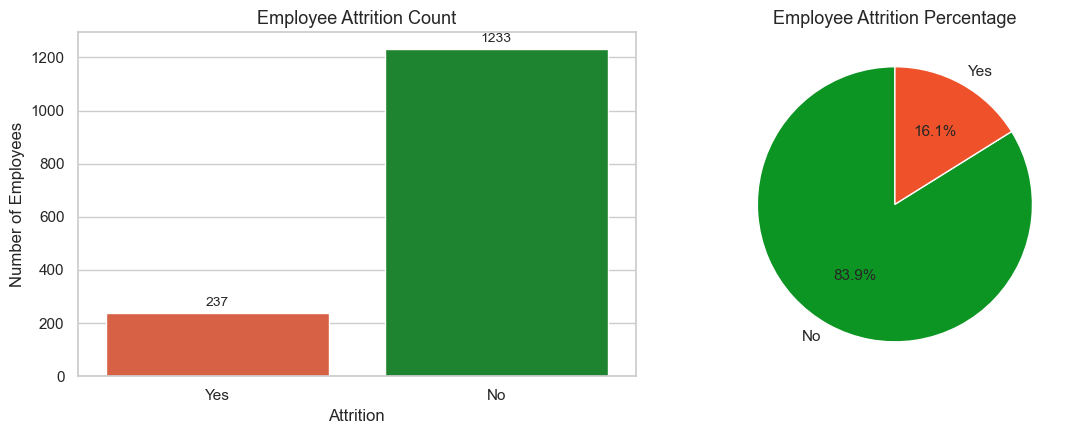

In [105]:
colors = ["#0D9524", "#EF522B"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(
    data=df,
    x="Attrition",
    hue="Attrition",
    palette={"No": colors[0], "Yes": colors[1]},
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Employee Attrition Count", fontsize=13)
axes[0].set_xlabel("Attrition")
axes[0].set_ylabel("Number of Employees")

for container in axes[0].containers:
    axes[0].bar_label(container, padding=3, fontsize=10)
counts = df["Attrition"].value_counts().reindex(["No", "Yes"])

axes[1].pie(
    counts,
    labels=counts.index,
    colors=colors,
    autopct="%1.1f%%",
    startangle=90,
    textprops={"fontsize": 11}
)

axes[1].set_title("Employee Attrition Percentage", fontsize=13)

plt.tight_layout()
plt.show()

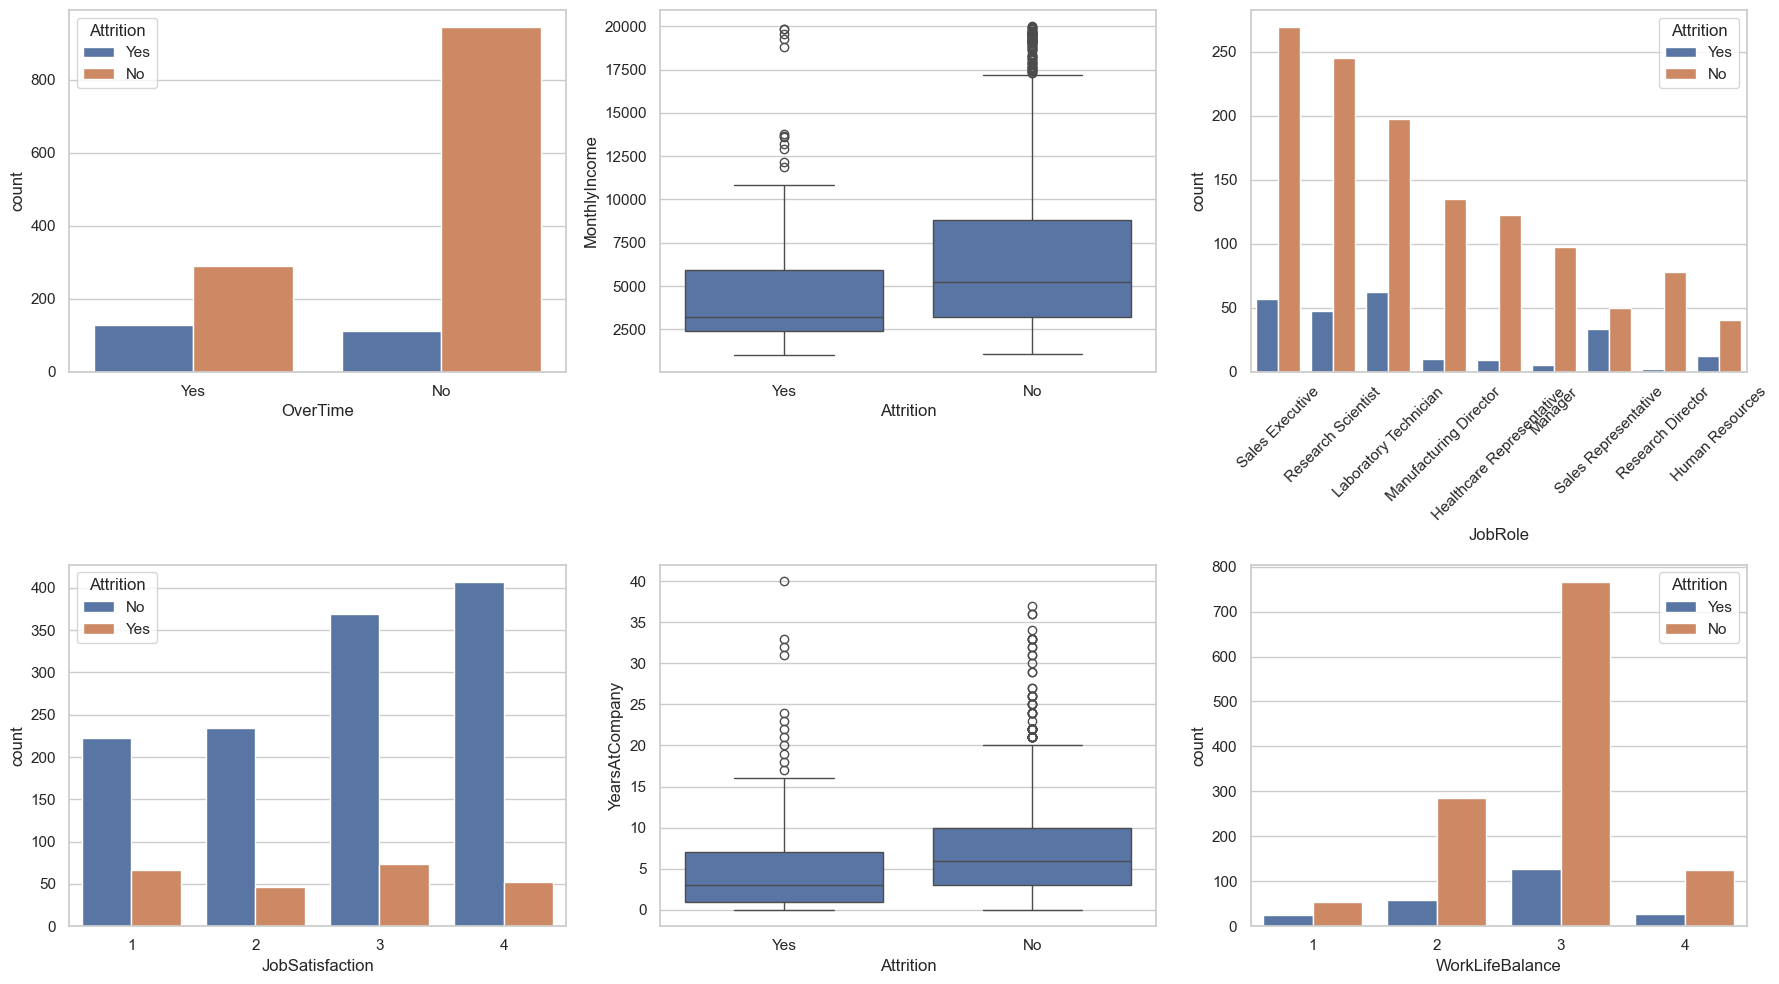

In [106]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.countplot(x='OverTime', hue='Attrition', data=df, ax=axes[0,0])
sns.countplot(x='JobRole', hue='Attrition', data=df, ax=axes[0,2])
axes[0,2].tick_params(axis='x', rotation=45)
sns.countplot(x='JobSatisfaction', hue='Attrition', data=df, ax=axes[1,0])

sns.boxplot(x='Attrition', y='MonthlyIncome', data=df, ax=axes[0,1])
sns.boxplot(x='Attrition', y='YearsAtCompany', data=df, ax=axes[1,1])
sns.countplot(x='WorkLifeBalance', hue='Attrition', data=df, ax=axes[1,2])

plt.tight_layout()
plt.show()

In [107]:
num_cols = df.select_dtypes(include=[np.number]).columns

valid_cols = df[num_cols].columns[
    df[num_cols].std() > 1e-10
]

z_scores = np.abs(stats.zscore(df[valid_cols]))
z_outliers = (z_scores > 3).sum().sum()

Q1 = df[valid_cols].quantile(0.25)
Q3 = df[valid_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
iqr_outliers = ((df[valid_cols] < lower_bound) | (df[valid_cols] > upper_bound)).sum().sum()

iso_forest = IsolationForest(contamination=0.05, random_state=RANDOM_SEED)
outliers_if = iso_forest.fit_predict(df[valid_cols])
if_outliers = (outliers_if == -1).sum()

print(f"Z-Score Outliers detected: {z_outliers}")
print(f"IQR Outliers detected: {iqr_outliers}")
print(f"Isolation Forest Outliers detected: {if_outliers}")

Z-Score Outliers detected: 110
IQR Outliers detected: 1024
Isolation Forest Outliers detected: 74


In [108]:
constant_cols = [c for c in df.columns if df[c].nunique() <= 1]
cols_to_drop = constant_cols + ['EmployeeNumber']
df_clean = df.drop(columns=cols_to_drop, axis=1)

print(f"Columns to drop: {cols_to_drop}")
print(f"Original shape: {df.shape}")
print(f"Cleaned shape: {df_clean.shape}")

Columns to drop: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
Original shape: (1470, 35)
Cleaned shape: (1470, 31)


In [109]:
df_eng = df_clean.copy()

df_eng['AgeWhenStarted'] = df_eng['Age'] - df_eng['YearsAtCompany']

df_eng['RelativeTenure'] = df_eng['YearsAtCompany'] / df_eng['Age']

df_eng['RelativeTenure'] = df_eng['RelativeTenure'].fillna(0)

print("Added features: 'AgeWhenStarted', 'RelativeTenure'")
display(df_eng[['Age', 'YearsAtCompany', 'AgeWhenStarted', 'RelativeTenure']].head())

Added features: 'AgeWhenStarted', 'RelativeTenure'


,Age,YearsAtCompany,AgeWhenStarted,RelativeTenure
0,41,6,35,0.146341
1,49,10,39,0.204082
2,37,0,37,0.000000
3,33,8,25,0.242424
4,27,2,25,0.074074


In [110]:
X = df_eng.drop('Attrition', axis=1)

y = df_eng['Attrition'].map({'Yes': 1, 'No': 0})

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Train Attrition ratio: {y_train.mean():.3f}")
print(f"Val Attrition ratio: {y_val.mean():.3f}")

Training set shape: (1176, 32)
Validation set shape: (294, 32)
Train Attrition ratio: 0.162
Val Attrition ratio: 0.160


In [111]:
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include=['object']).columns

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)])

In [112]:
def evaluate_model(model, X_val, y_val):
    """
    Evaluate a fitted classification pipeline on validation data.
    Positive class: Attrition = 1
    """

    y_pred = model.predict(X_val)

    results = {
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, pos_label=1, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_pred, pos_label=1, zero_division=0
        )
    }

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_val)[:, 1]
        results["ROC-AUC"] = roc_auc_score(y_val, y_score)

    elif hasattr(model, "decision_function"):
        y_score = model.decision_function(X_val)
        results["ROC-AUC"] = roc_auc_score(y_val, y_score)

    else:
        results["ROC-AUC"] = np.nan

    return results

In [113]:
dummy_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "classifier",
        DummyClassifier(
            strategy="most_frequent"
        )
    )
])

dummy_pipeline.fit(X_train, y_train)

results = {
    "Dummy": evaluate_model(
        dummy_pipeline, X_val, y_val
    )
}

In [114]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_SEED
    ),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_SEED
    ),
    "Random Forest": RandomForestClassifier(
        random_state=RANDOM_SEED
    ),
    "SVM Linear": SVC(
        kernel="linear",
        probability=True,
        random_state=RANDOM_SEED
    ),
    "SVM RBF": SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_SEED
    )
}

fitted_models = {
    "Dummy": dummy_pipeline
}

for name, model in models.items():

    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipe.fit(X_train, y_train)

    results[name] = evaluate_model(
        pipe, X_val, y_val
    )

    fitted_models[name] = pipe

comparison_df = (
    pd.DataFrame.from_dict(results, orient="index")
    .rename_axis("Model")
    .reset_index()
)

comparison_df = comparison_df.sort_values(
    by="Recall",
    ascending=False
).reset_index(drop=True)

display(
    comparison_df.style
    .format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-score": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
    .background_gradient(
        subset=["Recall", "F1-score", "ROC-AUC"],
        cmap="YlGn"
    )
)

/home/arian/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/arian/anaconda3/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.867,0.643,0.383,0.480,0.809
1,Decision Tree,0.772,0.300,0.319,0.309,0.589
2,SVM Linear,0.864,0.667,0.298,0.412,0.806
3,SVM RBF,0.861,0.750,0.191,0.305,0.815
4,KNN,0.840,0.500,0.149,0.230,0.619
5,Random Forest,0.833,0.429,0.128,0.197,0.805
6,Dummy,0.840,0.000,0.000,0.000,0.500


In [115]:
lr_baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_SEED
        )
    )
])

lr_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "classifier",
        LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_SEED
        )
    )
])

lr_smote = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_SEED)),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_SEED
        )
    )
])

lr_undersample = ImbPipeline(steps=[
    ("preprocessor", preprocessor),
    (
        "under",
        RandomUnderSampler(random_state=RANDOM_SEED)
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_SEED
        )
    )
])

imbalance_models = {
    "Baseline": lr_baseline,
    "Class Weights": lr_balanced,
    "SMOTE": lr_smote,
    "Undersampling": lr_undersample
}

imbalance_results = {}

for name, pipe in imbalance_models.items():

    pipe.fit(X_train, y_train)

    imbalance_results[name] = evaluate_model(
        pipe, X_val, y_val
    )

    fitted_models[name] = pipe

imbalance_df = (
    pd.DataFrame.from_dict(
        imbalance_results,
        orient="index"
    )
    .rename_axis("Strategy")
    .reset_index()
    .sort_values("Recall", ascending=False)
    .reset_index(drop=True)
)

display(
    imbalance_df.style
    .format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-score": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
    .background_gradient(
        subset=["Recall", "F1-score", "ROC-AUC"],
        cmap="YlGn"
    )
)

,Strategy,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Undersampling,0.745,0.348,0.681,0.460,0.780
1,Class Weights,0.779,0.385,0.638,0.480,0.803
2,SMOTE,0.782,0.387,0.617,0.475,0.798
3,Baseline,0.867,0.643,0.383,0.480,0.809


In [116]:
param_dist = {
    "classifier__C": loguniform(1e-3, 1e2),
    "classifier__solver": ["lbfgs", "liblinear"],
    "classifier__class_weight": [None, "balanced"],
    "classifier__max_iter": [1000, 2000, 3000]
}

search = RandomizedSearchCV(
    estimator=lr_undersample,
    param_distributions=param_dist,
    n_iter=30,
    scoring="recall",
    cv=3,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

search.fit(X_train, y_train)

print(f"Best CV Recall: {search.best_score_:.3f}")
print(f"Best Parameters: {search.best_params_}")

Best CV Recall: 0.774
Best Parameters: {'classifier__C': np.float64(0.0019145111285710716), 'classifier__class_weight': 'balanced', 'classifier__max_iter': 2000, 'classifier__solver': 'liblinear'}


In [117]:
search_results = pd.DataFrame(search.cv_results_)

search_results = search_results[
    [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "params"
    ]
].sort_values("rank_test_score")

display(
    search_results.head(10).style.format({
        "mean_test_score": "{:.3f}",
        "std_test_score": "{:.3f}",
        "mean_train_score": "{:.3f}"
    })
)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
4,1,0.774,0.008,0.792,"{'classifier__C': np.float64(0.0019145111285710716), 'classifier__class_weight': 'balanced', 'classifier__max_iter': 2000, 'classifier__solver': 'liblinear'}"
22,1,0.774,0.008,0.792,"{'classifier__C': np.float64(0.0016832027985721903), 'classifier__class_weight': 'balanced', 'classifier__max_iter': 1000, 'classifier__solver': 'liblinear'}"
12,3,0.768,0.007,0.792,"{'classifier__C': np.float64(0.0021147447960615704), 'classifier__class_weight': 'balanced', 'classifier__max_iter': 1000, 'classifier__solver': 'liblinear'}"
9,3,0.768,0.007,0.792,"{'classifier__C': np.float64(0.0028381292701126727), 'classifier__class_weight': 'balanced', 'classifier__max_iter': 3000, 'classifier__solver': 'liblinear'}"
6,5,0.768,0.027,0.792,"{'classifier__C': np.float64(0.033205591037519584), 'classifier__class_weight': 'balanced', 'classifier__max_iter': 1000, 'classifier__solver': 'liblinear'}"
0,6,0.768,0.028,0.803,"{'classifier__C': np.float64(0.0745934328572655), 'classifier__class_weight': None, 'classifier__max_iter': 3000, 'classifier__solver': 'lbfgs'}"
21,7,0.763,0.023,0.803,"{'classifier__C': np.float64(0.04292436152765813), 'classifier__class_weight': 'balanced', 'classifier__max_iter': 3000, 'classifier__solver': 'liblinear'}"
27,7,0.763,0.035,0.792,"{'classifier__C': np.float64(0.02933870049164395), 'classifier__class_weight': None, 'classifier__max_iter': 3000, 'classifier__solver': 'lbfgs'}"
25,7,0.763,0.035,0.792,"{'classifier__C': np.float64(0.0302947608528071), 'classifier__class_weight': None, 'classifier__max_iter': 1000, 'classifier__solver': 'lbfgs'}"
8,10,0.758,0.027,0.797,"{'classifier__C': np.float64(0.004982752357076452), 'classifier__class_weight': 'balanced', 'classifier__max_iter': 3000, 'classifier__solver': 'liblinear'}"


In [118]:
best_model = search.best_estimator_

best_results = evaluate_model(
    best_model, X_val, y_val
)

results["Tuned Logistic Regression + Undersampling"] = best_results
fitted_models["Tuned Logistic Regression + Undersampling"] = best_model

final_comparison = (
    pd.DataFrame.from_dict(results, orient="index")
    .rename_axis("Model")
    .reset_index()
    .sort_values("Recall", ascending=False)
    .reset_index(drop=True)
)

display(
    final_comparison.style
    .format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-score": "{:.3f}",
        "ROC-AUC": "{:.3f}"
    })
    .background_gradient(
        subset=["Recall", "F1-score", "ROC-AUC"],
        cmap="YlGn"
    )
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Tuned Logistic Regression + Undersampling,0.571,0.242,0.787,0.370,0.743
1,Logistic Regression,0.867,0.643,0.383,0.480,0.809
2,Decision Tree,0.772,0.300,0.319,0.309,0.589
3,SVM Linear,0.864,0.667,0.298,0.412,0.806
4,SVM RBF,0.861,0.750,0.191,0.305,0.815
5,KNN,0.840,0.500,0.149,0.230,0.619
6,Random Forest,0.833,0.429,0.128,0.197,0.805
7,Dummy,0.840,0.000,0.000,0.000,0.500


,precision,recall,f1-score,support
Stay,0.929,0.530,0.675,247.000
Leave,0.242,0.787,0.370,47.000
accuracy,0.571,0.571,0.571,0.571
macro avg,0.585,0.659,0.523,294.000
weighted avg,0.819,0.571,0.626,294.000


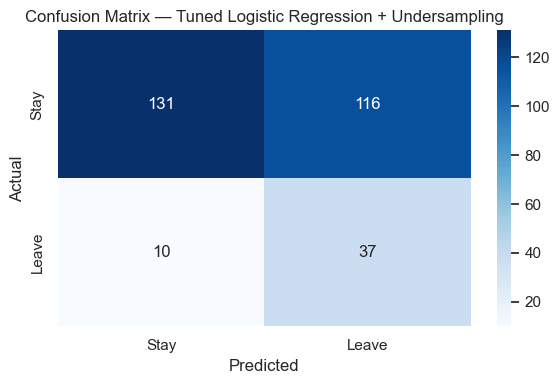

ROC-AUC: 0.743


In [119]:
val_preds = best_model.predict(X_val)
val_probs = best_model.predict_proba(X_val)[:, 1]

report_df = pd.DataFrame(
    classification_report(
        y_val,
        val_preds,
        labels=[0, 1],
        target_names=["Stay", "Leave"],
        output_dict=True,
        zero_division=0
    )
).T

display(
    report_df.style.format("{:.3f}")
)

cm = confusion_matrix(
    y_val,
    val_preds,
    labels=[0, 1]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stay", "Leave"],
    yticklabels=["Stay", "Leave"]
)

plt.title("Confusion Matrix — Tuned Logistic Regression + Undersampling")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc_score(y_val, val_probs):.3f}")

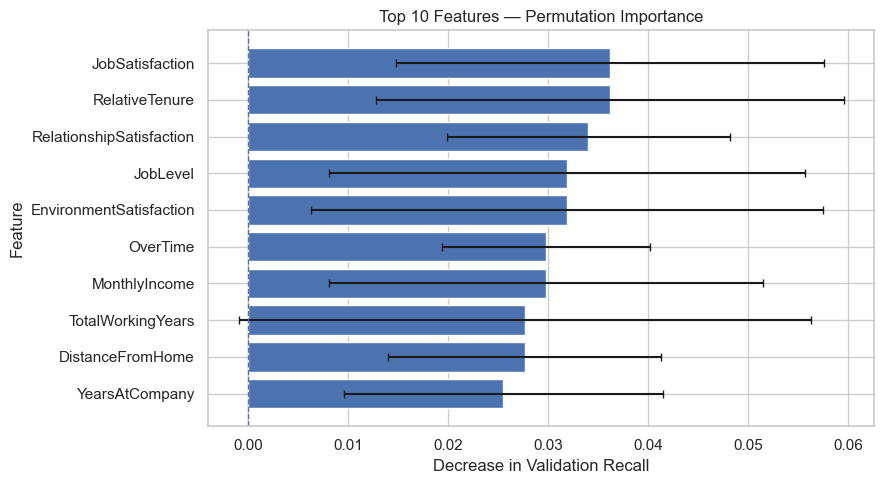

,Feature,Importance,Std
0,JobSatisfaction,0.0362,0.0214
1,RelativeTenure,0.0362,0.0234
2,RelationshipSatisfaction,0.0340,0.0141
3,JobLevel,0.0319,0.0238
4,EnvironmentSatisfaction,0.0319,0.0256
5,OverTime,0.0298,0.0104
6,MonthlyIncome,0.0298,0.0217
7,DistanceFromHome,0.0277,0.0136
8,TotalWorkingYears,0.0277,0.0286
9,YearsAtCompany,0.0255,0.0159


In [120]:
perm_result = permutation_importance(
    estimator=best_model,
    X=X_val,
    y=y_val,
    scoring="recall",
    n_repeats=10,
    random_state=RANDOM_SEED,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

top_features = importance_df.head(10).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    top_features["Feature"],
    top_features["Importance"],
    xerr=top_features["Std"],
    capsize=3
)

plt.axvline(0, linewidth=1, linestyle="--")

plt.title("Top 10 Features — Permutation Importance")
plt.xlabel("Decrease in Validation Recall")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(
    importance_df.head(10).style.format({
        "Importance": "{:.4f}",
        "Std": "{:.4f}"
    })
)

In [121]:
val_df = X_val.copy()

val_df["Actual"] = np.asarray(y_val)
val_df["Predicted"] = val_preds
val_df["Prob_Leave"] = val_probs

false_negatives = val_df[
    (val_df["Actual"] == 1) &
    (val_df["Predicted"] == 0)
].copy()

false_positives = val_df[
    (val_df["Actual"] == 0) &
    (val_df["Predicted"] == 1)
].copy()

print(f"False Negatives: {len(false_negatives)}")
print(f"False Positives: {len(false_positives)}")

candidate_features = [
    "MonthlyIncome",
    "OverTime",
    "JobSatisfaction",
    "Age",
    "YearsAtCompany"
]

available_features = [
    col for col in candidate_features
    if col in val_df.columns
]

print("\nTop 5 False Negatives:")

display(
    false_negatives[
        available_features + ["Prob_Leave"]
    ]
    .sort_values("Prob_Leave", ascending=False)
    .head(5)
)

print("\nTop 5 False Positives:")

display(
    false_positives[
        available_features + ["Prob_Leave"]
    ]
    .sort_values("Prob_Leave", ascending=False)
    .head(5)
)

False Negatives: 10
False Positives: 116

Top 5 False Negatives:


,MonthlyIncome,OverTime,JobSatisfaction,Age,YearsAtCompany,Prob_Leave
136,10650,No,4,51,4,0.477744
985,6179,Yes,3,31,10,0.470658
1186,4581,Yes,4,35,11,0.468830
562,2686,Yes,4,33,10,0.462764
779,2461,Yes,3,51,10,0.459364



Top 5 False Positives:


,MonthlyIncome,OverTime,JobSatisfaction,Age,YearsAtCompany,Prob_Leave
301,1200,No,3,18,0,0.613780
1311,1514,No,3,18,0,0.597022
1391,2858,No,1,38,1,0.590699
496,3447,No,3,21,3,0.588443
310,6410,No,1,31,2,0.588387


In [122]:
threshold_results = []

for threshold in np.arange(0.1, 0.91, 0.1):

    threshold_preds = (
        val_probs >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, threshold_preds, zero_division=0
        ),
        "Recall": recall_score(
            y_val, threshold_preds, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, threshold_preds, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.style
    .format({
        "Threshold": "{:.1f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-score": "{:.3f}"
    })
    .background_gradient(
        subset=["Recall", "F1-score"],
        cmap="YlGn"
    )
)

,Threshold,Precision,Recall,F1-score
0,0.1,0.160,1.000,0.276
1,0.2,0.160,1.000,0.276
2,0.3,0.156,0.957,0.269
3,0.4,0.175,0.936,0.295
4,0.5,0.242,0.787,0.370
5,0.6,0.900,0.191,0.316
6,0.7,0.000,0.000,0.000
7,0.8,0.000,0.000,0.000
8,0.9,0.000,0.000,0.000
